# Topic 1: Measures of Central Tendency and Dispersion
**BIT 4131 Statistical Computing and Reporting** | Dataset: UCI Student Performance (Portuguese course, `student-por.csv`, n = 649)
**Guiding question for the whole project:** what drives student performance? Here we describe the final grade `G3` (scale 0 to 20).

---
## 1. Theoretical explanation
- **Central tendency** says where the data "centre" is: the **mean** (balance point), the **median** (middle value, robust to outliers) and the **mode** (most frequent value).
- **Dispersion** says how spread out the data are: the **range**, **variance**, **standard deviation**, and the **quartiles / IQR** (spread of the middle 50%).
- When the mean and median differ noticeably, the distribution is skewed or has outliers.
- A **boxplot** shows the five-number summary (min, Q1, median, Q3, max) and flags outliers beyond the Tukey fences.

---
## 2. Mathematical formulation
For observations $x_1,\dots,x_n$:

$$\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i \qquad s^2=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2 \qquad s=\sqrt{s^2}$$

- **Median:** the middle order statistic (average of the two middle values if $n$ is even).
- **Mode:** the value with the highest frequency.
- **Quartiles:** $Q_1, Q_2, Q_3$ are the 25th, 50th and 75th percentiles; $\text{IQR}=Q_3-Q_1$.
- **Tukey fences:** outliers lie below $Q_1-1.5\,\text{IQR}$ or above $Q_3+1.5\,\text{IQR}$.
- **Coefficient of variation:** $CV=s/\bar{x}$ (spread relative to the mean).
- **Skewness:** $g_1=\dfrac{\frac1n\sum(x_i-\bar x)^3}{\left(\frac1n\sum(x_i-\bar x)^2\right)^{3/2}}$ (negative means a longer left tail).

---
## 3. Worked example (by hand, then in code)
Eight made-up grades: `12, 15, 11, 15, 18, 9, 15, 14`.

sorted     : [ 9 11 12 14 15 15 15 18]
mean       : 109 / 8 = 13.625
median     : (14 + 15) / 2 = 14.5
mode       : 15
sum sq dev : 55.875
variance   : 55.875 / 7 = 7.982
std dev    : 2.825
Manual results match numpy.
Q1 = 11.75, Q3 = 15.0, IQR = 3.25, fences = (6.875, 19.875), outliers: []


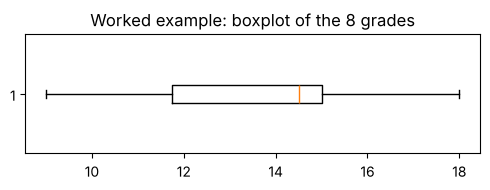

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

x = np.array([12, 15, 11, 15, 18, 9, 15, 14])
n = len(x)

# Step by step
mean = x.sum() / n
sorted_x = np.sort(x)                      # 9 11 12 14 15 15 15 18
median = (sorted_x[n//2 - 1] + sorted_x[n//2]) / 2
mode = pd.Series(x).mode()[0]
ss = ((x - mean) ** 2).sum()
variance = ss / (n - 1)
sd = variance ** 0.5

print("sorted     :", sorted_x)
print(f"mean       : {x.sum()} / {n} = {mean:.3f}")
print(f"median     : (14 + 15) / 2 = {median}")
print(f"mode       : {mode}")
print(f"sum sq dev : {ss:.3f}")
print(f"variance   : {ss:.3f} / {n-1} = {variance:.3f}")
print(f"std dev    : {sd:.3f}")

# Cross-check against library functions
assert np.isclose(mean, x.mean()) and np.isclose(variance, x.var(ddof=1)) and np.isclose(sd, x.std(ddof=1))
print("Manual results match numpy.")

# Quartiles, IQR and outlier fences (numpy's default linear interpolation)
q1, q3 = np.percentile(x, [25, 75]); iqr = q3 - q1
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}, fences = ({q1 - 1.5*iqr}, {q3 + 1.5*iqr}), outliers: {x[(x < q1 - 1.5*iqr) | (x > q3 + 1.5*iqr)]}")
plt.figure(figsize=(5, 2)); plt.boxplot(x, orientation="horizontal"); plt.title("Worked example: boxplot of the 8 grades")
plt.tight_layout(); plt.show()

---
## 4. Dataset analysis
Load the data and describe `G3`, the final grade.

In [2]:
df = pd.read_csv("../data/student-por.csv", sep=";")
print("Shape:", df.shape, "| missing values:", int(df.isna().sum().sum()))
g3 = df["G3"]

q1, q2, q3 = g3.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
lo_fence, hi_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr

summary = pd.Series({
    "n": g3.count(),
    "mean": g3.mean(),
    "median": g3.median(),
    "mode": g3.mode()[0],
    "min": g3.min(),
    "max": g3.max(),
    "range": g3.max() - g3.min(),
    "variance": g3.var(ddof=1),
    "std dev": g3.std(ddof=1),
    "CV": g3.std(ddof=1) / g3.mean(),
    "Q1": q1, "Q3": q3, "IQR": iqr,
    "lower fence": lo_fence, "upper fence": hi_fence,
    "skewness": stats.skew(g3),
    "outliers below fence": int((g3 < lo_fence).sum()),
    "outliers above fence": int((g3 > hi_fence).sum()),
    "grades of exactly 0": int((g3 == 0).sum()),
}).round(3)
print(summary.to_string())

Shape: (649, 33) | missing values: 0
n                       649.000
mean                     11.906
median                   12.000
mode                     11.000
min                       0.000
max                      19.000
range                    19.000
variance                 10.437
std dev                   3.231
CV                        0.271
Q1                       10.000
Q3                       14.000
IQR                       4.000
lower fence               4.000
upper fence              20.000
skewness                 -0.911
outliers below fence     16.000
outliers above fence      0.000
grades of exactly 0      15.000


In [3]:
# The same summary by school (GP vs MS)
by_school = df.groupby("school")["G3"].agg(
    n="count", mean="mean", median="median", sd="std",
    q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75)).round(3)
print(by_school)

          n    mean  median     sd    q1    q3
school                                        
GP      423  12.577    13.0  2.626  11.0  14.0
MS      226  10.650    11.0  3.834   9.0  13.0


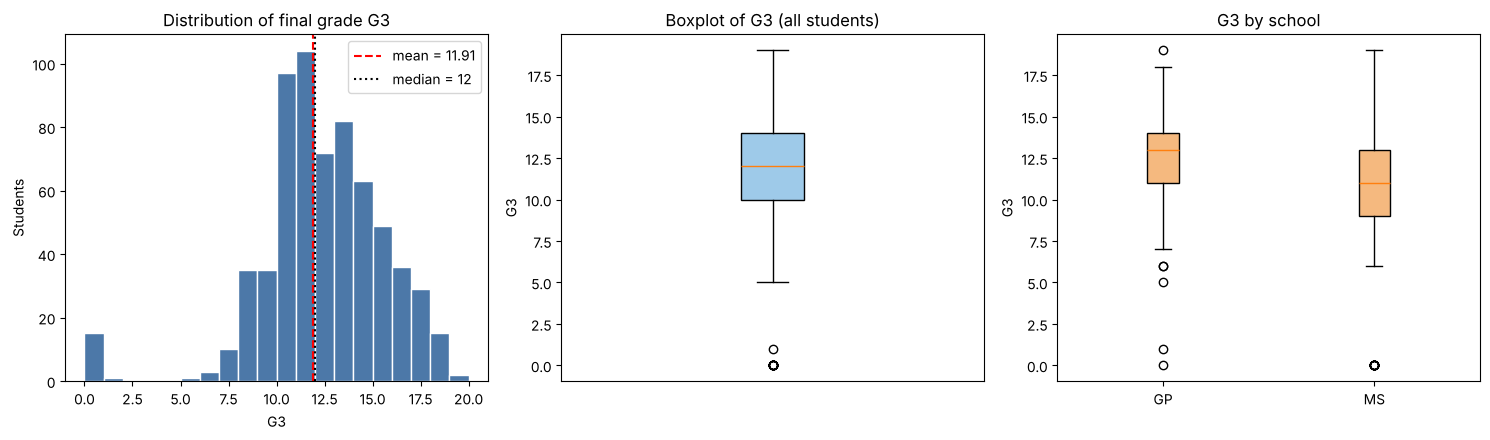

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Histogram with mean and median
axes[0].hist(g3, bins=range(0, 21), color="#4C78A8", edgecolor="white")
axes[0].axvline(g3.mean(), color="red", ls="--", label=f"mean = {g3.mean():.2f}")
axes[0].axvline(g3.median(), color="black", ls=":", label=f"median = {g3.median():.0f}")
axes[0].set(title="Distribution of final grade G3", xlabel="G3", ylabel="Students")
axes[0].legend()

# Boxplot, all students
axes[1].boxplot(g3, patch_artist=True, boxprops=dict(facecolor="#9ecae9"))
axes[1].set(title="Boxplot of G3 (all students)", ylabel="G3", xticks=[])

# Boxplot by school
data = [df.loc[df.school == s, "G3"] for s in ["GP", "MS"]]
axes[2].boxplot(data, tick_labels=["GP", "MS"], patch_artist=True, boxprops=dict(facecolor="#f5b97f"))
axes[2].set(title="G3 by school", ylabel="G3")

plt.tight_layout()
plt.savefig("figures/t01_g3_hist_boxplots.png", dpi=150)
plt.show()

---
## 5. Expected statistical output
The key results from the analysis above, with a plain-language meaning for each (full tables are printed in section 4; plots are saved to `figures/t01_g3_hist_boxplots.png`).

In [5]:
expected = pd.DataFrame([
    ("Mean", g3.mean(), "average final grade"),
    ("Median", g3.median(), "middle student; half score at or below this"),
    ("Mode", g3.mode()[0], "most common grade"),
    ("Variance", g3.var(ddof=1), "average squared distance from the mean"),
    ("Standard deviation", g3.std(ddof=1), "typical distance from the mean, in grade points"),
    ("Q1 / Q3", f"{q1:.0f} / {q3:.0f}", "25% score at or below Q1; 75% at or below Q3"),
    ("IQR", iqr, "spread of the middle 50% of students"),
    ("Outliers (below fence)", int((g3 < lo_fence).sum()), f"grades under {lo_fence:.0f}"),
], columns=["Measure", "Value", "Meaning"])
expected["Value"] = expected["Value"].map(lambda v: f"{v:.2f}" if isinstance(v, float) else str(v))
print(expected.to_string(index=False))

               Measure   Value                                         Meaning
                  Mean   11.91                             average final grade
                Median   12.00     middle student; half score at or below this
                  Mode      11                               most common grade
              Variance   10.44          average squared distance from the mean
    Standard deviation    3.23 typical distance from the mean, in grade points
               Q1 / Q3 10 / 14    25% score at or below Q1; 75% at or below Q3
                   IQR    4.00            spread of the middle 50% of students
Outliers (below fence)      16                                  grades under 4


---
## 6. Interpretation of results

In [6]:
print(f"1. Centre: mean = {g3.mean():.2f}, median = {g3.median():.0f}, mode = {g3.mode()[0]}. "
      f"The mean sits below the median, a sign of a longer LEFT tail (skewness = {stats.skew(g3):.2f}).")
print(f"2. Spread: sd = {g3.std():.2f} points; the middle 50% of students score between {q1:.0f} and {q3:.0f} (IQR = {iqr:.0f}).")
print(f"3. Outliers: {(g3 < lo_fence).sum()} students fall below the lower fence ({lo_fence:.0f}) and none above; "
      f"{(g3 == 0).sum()} of them scored exactly 0 (the data do not say why; they may reflect a missing final assessment rather than ability).")
print(f"4. Schools: GP averages {by_school.loc['GP','mean']:.2f} (sd {by_school.loc['GP','sd']:.2f}) versus "
      f"MS {by_school.loc['MS','mean']:.2f} (sd {by_school.loc['MS','sd']:.2f}), so MS students score lower and vary more. "
      "Topic 6 tests whether this gap is statistically significant.")

1. Centre: mean = 11.91, median = 12, mode = 11. The mean sits below the median, a sign of a longer LEFT tail (skewness = -0.91).
2. Spread: sd = 3.23 points; the middle 50% of students score between 10 and 14 (IQR = 4).
3. Outliers: 16 students fall below the lower fence (4) and none above; 15 of them scored exactly 0 (the data do not say why; they may reflect a missing final assessment rather than ability).
4. Schools: GP averages 12.58 (sd 2.63) versus MS 10.65 (sd 3.83), so MS students score lower and vary more. Topic 6 tests whether this gap is statistically significant.


**Take-aways**
- Typical student: about 12 out of 20, with half of all students between 10 and 14.
- The few very low grades (mostly zeros) pull the mean below the median, so the **median** describes a typical student better than the mean here.
- School MS has a lower centre and a larger spread than GP, which sets up the hypothesis test in Topic 6.